# Homework 4 — Evaluation Metrics

ML Zoomcamp 2026 | Lead scoring classification

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, train_test_split

DATA_PATH = Path('data/course_lead_scoring_2026.csv')
PLOTS_DIR = Path('plots')
PLOTS_DIR.mkdir(exist_ok=True)

In [2]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print(df.head())
print('Missing values:\n', df.isna().sum())

Shape: (5000, 9)
      lead_source       industry employment_status       location  \
0  organic_search     technology          employed         europe   
1    social_media     technology          employed  south_america   
2        referral         retail          employed         europe   
3        paid_ads  manufacturing           student            NaN   
4        referral  manufacturing           student  north_america   

   annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0        88160.0                         3                  4        0.64   
1        72688.0                         3                  7        0.72   
2        44697.0                         3                  4        0.58   
3            NaN                         3                  6        0.57   
4        24062.0                         4                  5        0.62   

   converted  
0          1  
1          1  
2          1  
3          0  
4          1  
Missing values:

In [3]:
target = 'converted'
feature_cols = [c for c in df.columns if c != target]

cat_cols = df[feature_cols].select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = df[feature_cols].select_dtypes(include=[np.number]).columns.tolist()

for col in cat_cols:
    df[col] = df[col].fillna('NA')
for col in num_cols:
    df[col] = df[col].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
print('Train/val/test:', df_train.shape, df_val.shape, df_test.shape)

Train/val/test: (3000, 9) (1000, 9) (1000, 9)


## Question 1 — Single-feature ROC AUC

In [4]:
q1_features = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
y_train = df_train[target].values
best_feat, best_auc = None, -1.0

for feat in q1_features:
    x = df_train[feat].values.astype(float)
    auc = roc_auc_score(y_train, x)
    neg = False
    if auc < 0.5:
        x = -x
        auc = roc_auc_score(y_train, x)
        neg = True
    print(f'{feat}: AUC={auc:.6f} (negated={neg})')
    if auc > best_auc:
        best_auc, best_feat = auc, feat
print('Best feature:', best_feat)

lead_score: AUC=0.788225 (negated=False)
number_of_courses_viewed: AUC=0.722989 (negated=False)
interaction_count: AUC=0.764920 (negated=False)
annual_income: AUC=0.608198 (negated=False)
Best feature: lead_score


## Question 2 — Logistic regression validation AUC

In [5]:
train_dicts = df_train[feature_cols].to_dict(orient='records')
val_dicts = df_val[feature_cols].to_dict(orient='records')
y_val = df_val[target].values

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_val_proba = model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_val_proba)
print(f'Validation ROC AUC: {val_auc:.3f}')

Validation ROC AUC: 0.732


## Questions 3 & 4 — Precision, recall, F1 vs threshold

Q3 threshold (min |P-R|): 0.63
Q4 threshold (max F1): 0.41, F1=0.7576


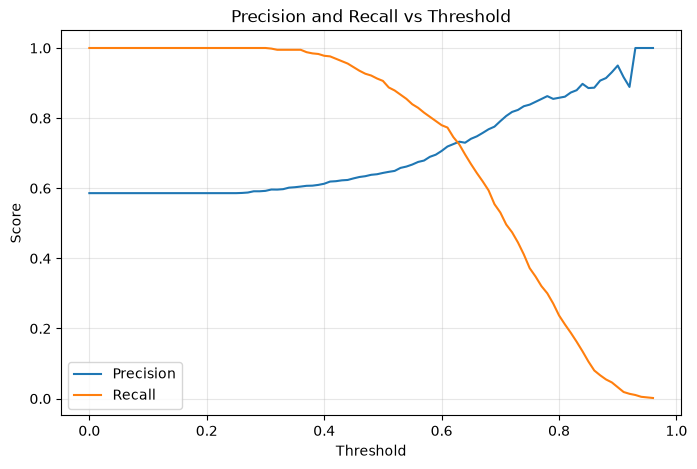

In [6]:
thresholds = np.arange(0.0, 1.01, 0.01)
precisions, recalls, f1s, valid_t = [], [], [], []

for t in thresholds:
    y_pred = (y_val_proba >= t).astype(int)
    tp = ((y_pred == 1) & (y_val == 1)).sum()
    fp = ((y_pred == 1) & (y_val == 0)).sum()
    fn = ((y_pred == 0) & (y_val == 1)).sum()
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    if prec == 0.0 and rec == 0.0:
        continue
    valid_t.append(t)
    precisions.append(prec)
    recalls.append(rec)
    f1s.append(2 * prec * rec / (prec + rec) if (prec + rec) else 0.0)

valid_t = np.array(valid_t)
precisions = np.array(precisions)
recalls = np.array(recalls)
f1s = np.array(f1s)

q3_i = np.argmin(np.abs(precisions - recalls))
q4_i = np.argmax(f1s)
print(f'Q3 threshold (min |P-R|): {valid_t[q3_i]:.2f}')
print(f'Q4 threshold (max F1): {valid_t[q4_i]:.2f}, F1={f1s[q4_i]:.4f}')

plt.figure(figsize=(8, 5))
plt.plot(valid_t, precisions, label='Precision')
plt.plot(valid_t, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(PLOTS_DIR / 'precision_recall_vs_threshold.png', dpi=150, bbox_inches='tight')
plt.show()

## Question 5 — 5-fold CV (C=1)

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)
full_dicts = df_full_train[feature_cols].to_dict(orient='records')
y_full = df_full_train[target].values
fold_aucs = []

for tr_idx, va_idx in kf.split(df_full_train):
    tr_d = [full_dicts[i] for i in tr_idx]
    va_d = [full_dicts[i] for i in va_idx]
    dv_f = DictVectorizer(sparse=False)
    X_tr = dv_f.fit_transform(tr_d)
    X_va = dv_f.transform(va_d)
    m = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    m.fit(X_tr, y_full[tr_idx])
    proba = m.predict_proba(X_va)[:, 1]
    fold_aucs.append(roc_auc_score(y_full[va_idx], proba))

fold_aucs = np.array(fold_aucs)
print('Fold AUCs:', fold_aucs)
print(f'Mean: {fold_aucs.mean():.6f}, Std: {fold_aucs.std():.6f}')

Fold AUCs: [0.7305601  0.72957261 0.73634281 0.74124547 0.72091386]
Mean: 0.731727, Std: 0.006853


## Question 6 — CV for multiple C values

In [8]:
c_values = [0.000001, 0.001, 1]
results = []
for c in c_values:
    folds = []
    for tr_idx, va_idx in kf.split(df_full_train):
        tr_d = [full_dicts[i] for i in tr_idx]
        va_d = [full_dicts[i] for i in va_idx]
        dv_f = DictVectorizer(sparse=False)
        X_tr = dv_f.fit_transform(tr_d)
        X_va = dv_f.transform(va_d)
        m = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        m.fit(X_tr, y_full[tr_idx])
        folds.append(roc_auc_score(y_full[va_idx], m.predict_proba(X_va)[:, 1]))
    mean_r, std_r = round(float(np.mean(folds)), 3), round(float(np.std(folds)), 3)
    results.append((c, mean_r, std_r))
    print(f'C={c}: mean={mean_r}, std={std_r}, folds={folds}')

results.sort(key=lambda x: (-x[1], x[2], x[0]))
print('Best C:', results[0][0])

C=1e-06: mean=0.617, std=0.019, folds=[0.5941004654148612, 0.6402137243565715, 0.6001570384100505, 0.6364466933726896, 0.6127532038032245]


C=0.001: mean=0.749, std=0.01, folds=[0.7504349221633766, 0.7475333388395098, 0.7583539285346514, 0.7584127166669861, 0.7311259818106656]


C=1: mean=0.732, std=0.007, folds=[0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Best C: 0.001
